<a href="https://colab.research.google.com/github/twyeh/university-physics/blob/main/%E5%96%AE%E6%93%BA%E5%AF%A6%E9%A9%97%E6%93%AC%E5%90%88%E5%88%86%E6%9E%90%E7%AF%84%E4%BE%8B.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 單擺實驗決定重力加速度程式
此程式針對三個不同擺長，各進行 10 次週期測量，計算其平均值、標準偏差，並進行線性擬合求出重力加速度 $g$。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress

# 1. 輸入實驗數據：3 個不同擺長 (L, 單位：公尺)
L = np.array([0.40, 0.70, 1.00])

# 每個擺長對應的 10 次單次週期測量值 (T, 單位：秒)
# 這裡提供一組符合物理規律的模擬實驗數據
T_measurements = np.array([
    # L = 0.40 m 的 10 次週期測量值
    [1.25, 1.28, 1.27, 1.26, 1.24, 1.29, 1.26, 1.27, 1.25, 1.28],
    # L = 0.70 m 的 10 次週期測量值
    [1.67, 1.69, 1.68, 1.66, 1.70, 1.67, 1.68, 1.69, 1.65, 1.67],
    # L = 1.00 m 的 10 次週期測量值
    [2.01, 2.03, 1.99, 2.02, 2.00, 2.04, 2.01, 2.02, 1.98, 2.02]
])

# 2. 計算平均值與標準偏差
T_mean = np.mean(T_measurements, axis=1)
T_std = np.std(T_measurements, axis=1, ddof=1)  # 使用樣本標準偏差 (ddof=1)

# 3. 計算 T^2 及其傳播誤差 (delta(T^2) 約等於 2 * T * delta_T)
T_squared = T_mean ** 2
T_squared_err = 2 * T_mean * T_std

# 輸出統計結果
print("=== 實驗數據統計 ===")
for i in range(len(L)):
    print(f"擺長 L = {L[i]:.2f} m:")
    print(f"  10次測量值: {T_measurements[i]}")
    print(f"  平均週期 T = {T_mean[i]:.4f} s")
    print(f"  標準偏差 S_T = {T_std[i]:.4f} s")
    print(f"  週期平方 T^2 = {T_squared[i]:.4f} ± {T_squared_err[i]:.4f} s^2\n")

=== 實驗數據統計 ===
擺長 L = 0.40 m:
  10次測量值: [1.25 1.28 1.27 1.26 1.24 1.29 1.26 1.27 1.25 1.28]
  平均週期 T = 1.2650 s
  標準偏差 S_T = 0.0158 s
  週期平方 T^2 = 1.6002 ± 0.0400 s^2

擺長 L = 0.70 m:
  10次測量值: [1.67 1.69 1.68 1.66 1.7  1.67 1.68 1.69 1.65 1.67]
  平均週期 T = 1.6760 s
  標準偏差 S_T = 0.0151 s
  週期平方 T^2 = 2.8090 ± 0.0505 s^2

擺長 L = 1.00 m:
  10次測量值: [2.01 2.03 1.99 2.02 2.   2.04 2.01 2.02 1.98 2.02]
  平均週期 T = 2.0120 s
  標準偏差 S_T = 0.0181 s
  週期平方 T^2 = 4.0481 ± 0.0730 s^2



In [2]:
# 4. 線性擬合分析：T^2 = m * L + c
slope, intercept, r_value, p_value, std_err = linregress(L, T_squared)

# 由斜率 m = 4 * pi^2 / g 導出 g = 4 * pi^2 / m
g_calculated = (4 * np.pi**2) / slope

print("=== 擬合分析結果 ===")
print(f"線性擬合斜率 (m): {slope:.4f} s^2/m")
print(f"截距 (c): {intercept:.4f} s^2")
print(f"判定係數 (R^2): {r_value**2:.6f}")
print(f"估算之重力加速度 g: {g_calculated:.4f} m/s^2")

# 與標準重力加速度 9.80665 m/s^2 比較
g_standard = 9.80665
error_percent = abs(g_calculated - g_standard) / g_standard * 100
print(f"與標準值 ({g_standard} m/s^2) 的相對誤差: {error_percent:.2f}%")

=== 擬合分析結果 ===
線性擬合斜率 (m): 4.0799 s^2/m
截距 (c): -0.0368 s^2
判定係數 (R^2): 0.999949
估算之重力加速度 g: 9.6764 m/s^2
與標準值 (9.80665 m/s^2) 的相對誤差: 1.33%


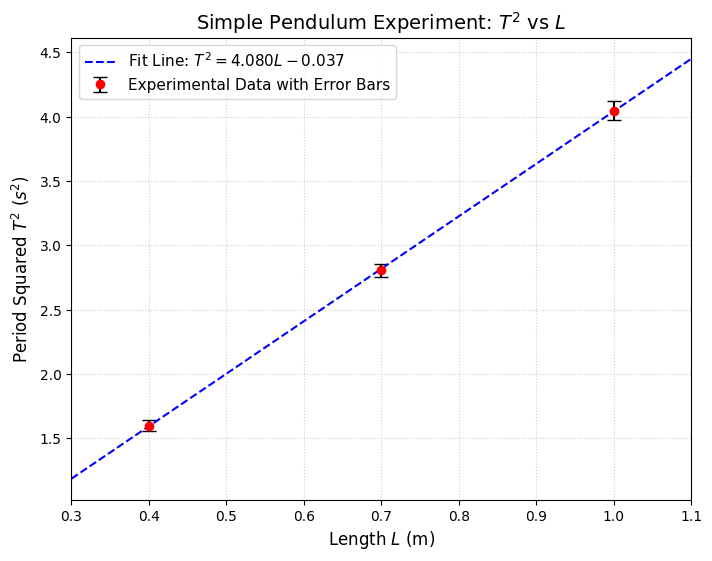

In [3]:
# 5. 繪製物理擬合圖表與誤差棒
plt.figure(figsize=(8, 6))

# 繪製實驗數據點與誤差棒 (Error Bars)
plt.errorbar(L, T_squared, yerr=T_squared_err, fmt='ro', ecolor='black',
             capsize=5, elinewidth=1.5, label='Experimental Data with Error Bars')

# 繪製最佳擬合線
L_fit = np.linspace(0.3, 1.1, 100)
T_squared_fit = slope * L_fit + intercept
plt.plot(L_fit, T_squared_fit, 'b--', label=f'Fit Line: $T^2 = {slope:.3f}L {intercept:+.3f}$')

plt.title('Simple Pendulum Experiment: $T^2$ vs $L$', fontsize=14)
plt.xlabel('Length $L$ (m)', fontsize=12)
plt.ylabel('Period Squared $T^2$ ($s^2$)', fontsize=12)
plt.xlim(0.3, 1.1)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11)
plt.show()